<a href="https://colab.research.google.com/github/FrancoPanico/glioblastoma-mri-seg-mgmt/blob/N4ITK/N4ITK_Preprocessing_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# N4ITK Bias Field Correction & Intensity Normalization Pipeline

**Course:** Applied AI in Biomedicine — Final Assignment  
**Input & Output Directory:** `Applied AI in Biomedicine/assignmentN4ITK`

### Operatività su Google Colab
- **Runtime consigliato:** `Runtime -> Cambia tipo di runtime -> CPU` (SimpleITK esegue N4ITK su CPU, evitando di consumare quota GPU).
- **Input letti da `assignmentN4ITK`:** `training_metadata.xlsx` e `training_images/<ID>/{t1,t1ce,t2,flair,seg}.nii.gz`.
- **Output salvati in `assignmentN4ITK`:** `preprocessed_n4itk/<ID>/` (con checkpoint automatico per riprendere l'elaborazione in caso di disconnessione).

## 1. Installazione librerie e collegamento a Google Drive

In [1]:
!pip install -q SimpleITK nibabel pandas openpyxl tqdm matplotlib

import os
import shutil
from concurrent.futures import ProcessPoolExecutor, as_completed
import numpy as np
import pandas as pd
import SimpleITK as sitk
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from google.colab import drive

drive.mount('/content/drive')

CANDIDATE_DIRS = [
    '/content/drive/MyDrive/Applied AI in Biomedicine/assignmentN4ITK',
    '/content/drive/MyDrive/assignmentN4ITK',
]
BASE_DIR = next((p for p in CANDIDATE_DIRS if os.path.exists(p)), None)
assert BASE_DIR is not None, (
    "Cartella 'assignmentN4ITK' non trovata su Google Drive. "
    "Verifica che sia presente in 'MyDrive/Applied AI in Biomedicine/assignmentN4ITK'."
)

META_PATH = os.path.join(BASE_DIR, 'training_metadata.xlsx')
IMG_DIR = os.path.join(BASE_DIR, 'training_images')
OUT_DIR = os.path.join(BASE_DIR, 'preprocessed_n4itk')
os.makedirs(OUT_DIR, exist_ok=True)

assert os.path.exists(META_PATH), f'File metadati non trovato: {META_PATH}'
assert os.path.exists(IMG_DIR), f'Cartella immagini non trovata: {IMG_DIR}'

meta_df = pd.read_excel(META_PATH)
print(f'BASE_DIR attivo: {BASE_DIR}')
print(f'Output directory: {OUT_DIR}')
print(f'Totale pazienti nei metadati: {len(meta_df)}')
meta_df.head()

Mounted at /content/drive
BASE_DIR attivo: /content/drive/MyDrive/Applied AI in Biomedicine/assignmentN4ITK
Output directory: /content/drive/MyDrive/Applied AI in Biomedicine/assignmentN4ITK/preprocessed_n4itk
Totale pazienti nei metadati: 1384


,ID,MGMT value,Cohort ID
0,1,NaN,1
1,2,NaN,1
2,3,0.0,1
3,4,NaN,1
4,5,NaN,2


## 2. Configurazione parametri e funzione N4ITK (+ Z-score opzionale)

In [2]:
MODALITIES = ['t1', 't1ce', 't2', 'flair']

# Parametri N4ITK (Tustison et al., 2010)
SHRINK_FACTOR = 4
NUM_ITERATIONS = [50, 50, 30, 20]
SPLINE_ORDER = 3
CONTROL_POINTS = [4, 4, 4]

# Se True, applica clipping [0.5, 99.5] percentile + Z-score sui voxel cerebrali non-zero
# dopo la correzione N4ITK (consigliato per dataset multicentrici).
APPLY_ZSCORE = True


def apply_n4itk_volume(
    input_path: str,
    shrink_factor: int = SHRINK_FACTOR,
    num_iterations: list = None,
    spline_order: int = SPLINE_ORDER,
    control_points: list = None,
    apply_zscore: bool = APPLY_ZSCORE,
):
    """
    Applica la correzione del bias field N4ITK su un volume MRI 3D NIfTI
    preservando spacing, origin e direction nativi (1x1x1 mm).
    """
    if num_iterations is None:
        num_iterations = [50, 50, 30, 20]
    if control_points is None:
        control_points = [4, 4, 4]

    img = sitk.ReadImage(input_path, sitk.sitkFloat32)

    # Maschera cerebrale sui voxel non-zero (volumi già skull-stripped)
    mask = sitk.Cast(img > 0, sitk.sitkUInt8)
    if sitk.GetArrayViewFromImage(mask).sum() == 0:
        mask = sitk.OtsuThreshold(img, 0, 1, 200)

    # Sottocampionamento per velocizzare la stima del campo B-spline cubico
    if shrink_factor > 1:
        img_shrunk = sitk.Shrink(img, [shrink_factor] * img.GetDimension())
        mask_shrunk = sitk.Shrink(mask, [shrink_factor] * mask.GetDimension())
    else:
        img_shrunk = img
        mask_shrunk = mask

    corrector = sitk.N4BiasFieldCorrectionImageFilter()
    corrector.SetMaximumNumberOfIterations(num_iterations)
    corrector.SetSplineOrder(spline_order)
    corrector.SetNumberOfControlPoints(control_points)
    corrector.SetConvergenceThreshold(1e-6)

    # Stima del campo a bassa frequenza sul volume ridotto
    _ = corrector.Execute(img_shrunk, mask_shrunk)

    # Ricostruzione del log-bias field alla risoluzione piena 1x1x1 mm
    log_bias_field = corrector.GetLogBiasFieldAsImage(img)
    bias_field = sitk.Exp(log_bias_field)

    # Rimozione moltiplicativa del bias field e azzeramento sfondo
    img_corrected = img / bias_field
    img_corrected = sitk.Mask(img_corrected, mask)
    img_corrected.CopyInformation(img)

    # Standardizzazione subject-level (clipping 0.5-99.5 + Z-score sui voxel cerebrali)
    if apply_zscore:
        arr = sitk.GetArrayFromImage(img_corrected)
        brain_mask = sitk.GetArrayFromImage(mask) > 0
        if np.any(brain_mask):
            brain_vals = arr[brain_mask]
            p_low, p_high = np.percentile(brain_vals, [0.5, 99.5])
            arr_clipped = np.clip(arr, p_low, p_high)
            mean_val = arr_clipped[brain_mask].mean()
            std_val = arr_clipped[brain_mask].std() + 1e-8
            arr_norm = np.where(
                brain_mask, (arr_clipped - mean_val) / std_val, 0.0
            ).astype(np.float32)
            img_corrected = sitk.GetImageFromArray(arr_norm)
            img_corrected.CopyInformation(img)

    return img, img_corrected, bias_field

## 3. Controllo Qualità (QC) visivo su un paziente campione
Genera e salva in `assignmentN4ITK/preprocessed_n4itk/` la figura comparativa tra volume originale, campo $B_1$ stimato, volume post-N4ITK e distribuzione delle intensità.

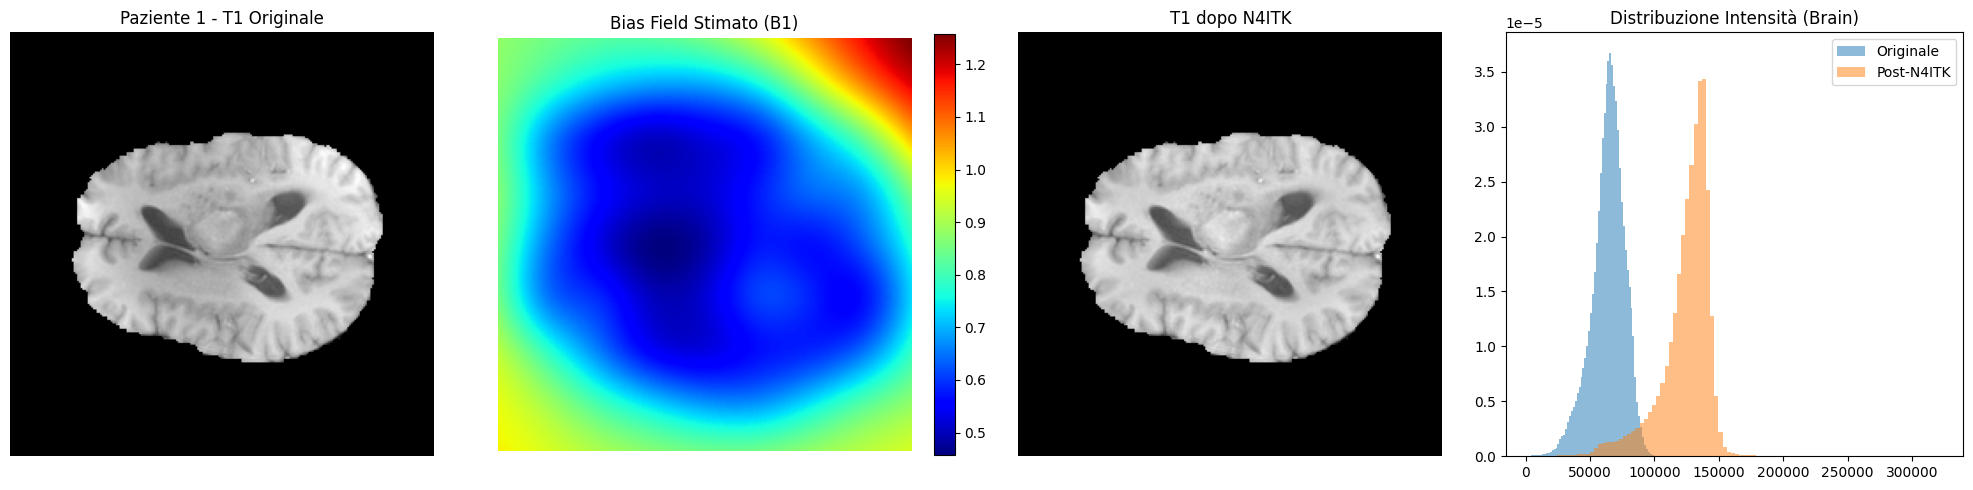

Figura QC salvata in: /content/drive/MyDrive/Applied AI in Biomedicine/assignmentN4ITK/preprocessed_n4itk/qc_n4itk_patient_1.png


In [3]:
sample_id = str(int(meta_df['ID'].iloc[0]))
sample_t1_path = os.path.join(IMG_DIR, sample_id, 't1.nii.gz')

orig_img, corr_img, bias_img = apply_n4itk_volume(
    sample_t1_path,
    shrink_factor=SHRINK_FACTOR,
    apply_zscore=False,  # Visualizziamo l'effetto puro della correzione N4ITK
)

orig_arr = sitk.GetArrayFromImage(orig_img)
corr_arr = sitk.GetArrayFromImage(corr_img)
bias_arr = sitk.GetArrayFromImage(bias_img)
z_mid = orig_arr.shape[0] // 2

fig, axes = plt.subplots(1, 4, figsize=(20, 5))

axes[0].imshow(np.rot90(orig_arr[z_mid]), cmap='gray')
axes[0].set_title(f'Paziente {sample_id} - T1 Originale')
axes[0].axis('off')

im_bias = axes[1].imshow(np.rot90(bias_arr[z_mid]), cmap='jet')
axes[1].set_title('Bias Field Stimato (B1)')
axes[1].axis('off')
plt.colorbar(im_bias, ax=axes[1], fraction=0.046)

axes[2].imshow(np.rot90(corr_arr[z_mid]), cmap='gray')
axes[2].set_title('T1 dopo N4ITK')
axes[2].axis('off')

axes[3].hist(orig_arr[orig_arr > 0].ravel(), bins=100, alpha=0.5, label='Originale', density=True)
axes[3].hist(corr_arr[corr_arr > 0].ravel(), bins=100, alpha=0.5, label='Post-N4ITK', density=True)
axes[3].set_title('Distribuzione Intensità (Brain)')
axes[3].legend()

plt.tight_layout()
qc_path = os.path.join(OUT_DIR, f'qc_n4itk_patient_{sample_id}.png')
plt.savefig(qc_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Figura QC salvata in: {qc_path}')

## 4. Elaborazione batch parallela su tutti i pazienti (con checkpoint)
Salva tutti i volumi preprocessati in `assignmentN4ITK/preprocessed_n4itk/<ID>/` copiando intatta l'eventuale maschera `seg.nii.gz`.

In [4]:
def process_single_patient(patient_id: str, apply_zscore: bool = APPLY_ZSCORE):
    # Evita oversubscription dei thread dentro ciascun processo worker
    sitk.ProcessObject.SetGlobalDefaultNumberOfThreads(1)

    src_patient_dir = os.path.join(IMG_DIR, patient_id)
    dst_patient_dir = os.path.join(OUT_DIR, patient_id)

    if not os.path.isdir(src_patient_dir):
        return patient_id, 'missing_src'

    # Checkpoint: salta il paziente se tutte e 4 le sequenze sono già presenti
    expected_outputs = [os.path.join(dst_patient_dir, f'{m}.nii.gz') for m in MODALITIES]
    if all(os.path.exists(p) for p in expected_outputs):
        return patient_id, 'skipped'

    os.makedirs(dst_patient_dir, exist_ok=True)
    tmp_dir = f'/tmp/n4_{patient_id}'
    os.makedirs(tmp_dir, exist_ok=True)

    try:
        for mod in MODALITIES:
            src_file = os.path.join(src_patient_dir, f'{mod}.nii.gz')
            tmp_out = os.path.join(tmp_dir, f'{mod}.nii.gz')
            dst_out = os.path.join(dst_patient_dir, f'{mod}.nii.gz')

            if not os.path.exists(dst_out):
                _, corr_img, _ = apply_n4itk_volume(
                    src_file,
                    shrink_factor=SHRINK_FACTOR,
                    apply_zscore=apply_zscore,
                )
                sitk.WriteImage(corr_img, tmp_out, useCompression=True)
                shutil.move(tmp_out, dst_out)

        # Copia intatta la ground-truth segmentation mask se presente
        src_seg = os.path.join(src_patient_dir, 'seg.nii.gz')
        dst_seg = os.path.join(dst_patient_dir, 'seg.nii.gz')
        if os.path.exists(src_seg) and not os.path.exists(dst_seg):
            shutil.copy2(src_seg, dst_seg)

        return patient_id, 'done'
    finally:
        shutil.rmtree(tmp_dir, ignore_errors=True)


patient_ids = [str(int(pid)) for pid in meta_df['ID'].tolist()]
num_workers = max(1, (os.cpu_count() or 2))
print(f'Avvio preprocessing N4ITK (apply_zscore={APPLY_ZSCORE}) su {len(patient_ids)} pazienti con {num_workers} worker CPU...')

stats = {'done': 0, 'skipped': 0, 'missing_src': 0}
with ProcessPoolExecutor(max_workers=num_workers) as executor:
    futures = {
        executor.submit(process_single_patient, pid, APPLY_ZSCORE): pid
        for pid in patient_ids
    }
    for future in tqdm(as_completed(futures), total=len(futures)):
        _, status = future.result()
        stats[status] = stats.get(status, 0) + 1

print('Preprocessing completato! Riepilogo:', stats)

Avvio preprocessing N4ITK (apply_zscore=True) su 1384 pazienti con 2 worker CPU...


  0%|          | 0/1384 [00:00<?, ?it/s]

Preprocessing completato! Riepilogo: {'done': 29, 'skipped': 1355, 'missing_src': 0}
